In [1]:
#!pip install git+https://github.com/facebookresearch/segment-anything.git

In [1]:
import os
import sys

# TODO: Fill in the Google Drive path where you uploaded the assignment
# Example: If you create a WI2022 folder and put all the files under A5 folder, then "WI2022/A5"
dir_paht = '../../learning/segment_anything/Wide Field Images Cropped/'
#GOOGLE_DRIVE_PATH = os.path.join("drive", "Shared drives", "M4AM", "Image Database",GOOGLE_DRIVE_PATH_AFTER_MYDRIVE)

#GOOGLE_DRIVE_PATH_AFTER_MYDRIVE_2 = 'EECS_598/A5'
#GOOGLE_DRIVE_PATH_2 = os.path.join("drive", "My Drive", GOOGLE_DRIVE_PATH_AFTER_MYDRIVE_2)

#GOOGLE_DRIVE_PATH_AFTER_MYDRIVE_2 = 'A5'
#GOOGLE_DRIVE_PATH_2 = os.path.join("drive", "My Drive", "EECS_598",GOOGLE_DRIVE_PATH_AFTER_MYDRIVE_2)

print(os.listdir(dir_paht))


# Add to sys so we can import .py files.
sys.path.append(dir_paht)

['MEC_02_038_OPTIR_quartz_2.jpg', 'MEC_02_038_OPTIR_quartz_3.jpg', 'MEC_02_038_OPTIR_quartz_1.jpg', 'MEC_02_036_OPTIR_quartz_5.jpg', 'MEC_02_036_OPTIR_quartz_4.jpg', 'MEC_02_038_OPTIR_quartz_4.jpg', 'MEC_02_033_20x_FOV2.jpg', 'MEC_02_036_OPTIR_quartz_1.jpg', 'MEC_02_038_OPTIR_quartz_5.jpg', 'MEC_02_036_OPTIR_quartz_3.jpg', 'MEC_02_036_OPTIR_quartz_2.jpg', 'MEC_02_035_OPTIR_Si_4.jpg', 'MEC_02_033_50x_FOV2.jpg', 'MEC_02_035_OPTIR_Si_2.jpg', 'MEC_02_035_OPTIR_Si_3.jpg', 'MEC_02_035_OPTIR_Si_1.jpg', 'MEC_02_033_20x_FOV.jpg', 'MEC_02_033_50x_FOV.jpg']


In [2]:
import torchvision.transforms as T
from PIL import Image
import torch
from torchvision import transforms
from torchvision.utils import draw_segmentation_masks
import torchvision.transforms.functional as F

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import segment_anything
from segment_anything import SamPredictor, sam_model_registry, SamAutomaticMaskGenerator

In [3]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import cv2
from tqdm import trange, tqdm

In [4]:
if torch.cuda.is_available():
    print("Good to go!")
    DEVICE = torch.device("cuda")
else:
    print("Please set GPU via Edit -> Notebook Settings.")
    DEVICE = torch.device("cpu")

Please set GPU via Edit -> Notebook Settings.


In [5]:
sam = sam_model_registry["default"](checkpoint=os.path.join("../../learning/segment_anything/", "sam_vit_h_4b8939.pth"))
sam.to(device=DEVICE)

Sam(
  (image_encoder): ImageEncoderViT(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 1280, kernel_size=(16, 16), stride=(16, 16))
    )
    (blocks): ModuleList(
      (0): Block(
        (norm1): LayerNorm((1280,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=1280, out_features=3840, bias=True)
          (proj): Linear(in_features=1280, out_features=1280, bias=True)
        )
        (norm2): LayerNorm((1280,), eps=1e-06, elementwise_affine=True)
        (mlp): MLPBlock(
          (lin1): Linear(in_features=1280, out_features=5120, bias=True)
          (lin2): Linear(in_features=5120, out_features=1280, bias=True)
          (act): GELU(approximate='none')
        )
      )
      (1): Block(
        (norm1): LayerNorm((1280,), eps=1e-06, elementwise_affine=True)
        (attn): Attention(
          (qkv): Linear(in_features=1280, out_features=3840, bias=True)
          (proj): Linear(in_features=1280, out_features=1280, b

In [6]:
image = Image.open(os.path.join(dir_paht, 'MEC_02_038_OPTIR_quartz_2.jpg'))
image = image.convert("RGB")
trans_img = T.Resize(size=224)(image)
transform = transforms.Compose([transforms.ToTensor()])
image_tensor = transform(image)
image_array = np.asarray(image)

In [7]:
images = [cv2.imread(os.path.join(dir_paht, x)) if x[-3:] == 'jpg' else None 
          for x in os.listdir(dir_paht)]
        
#image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [372]:
images = [cv2.cvtColor(image, cv2.COLOR_BGR2RGB) for image in images]

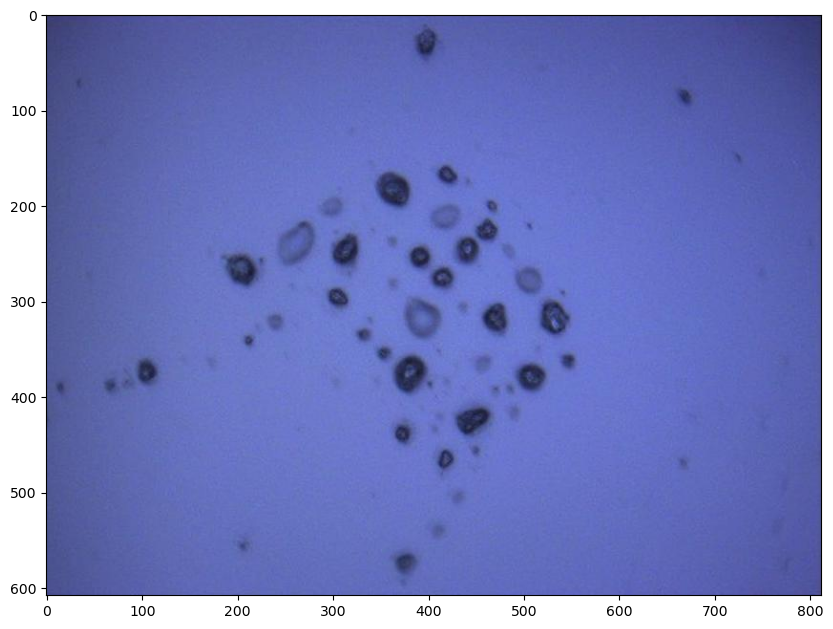

In [37]:
plt.figure(figsize=(10,10))
plt.imshow(images[1])

In [38]:
mask_generator = SamAutomaticMaskGenerator(sam)
mask = mask_generator.generate(images[1])

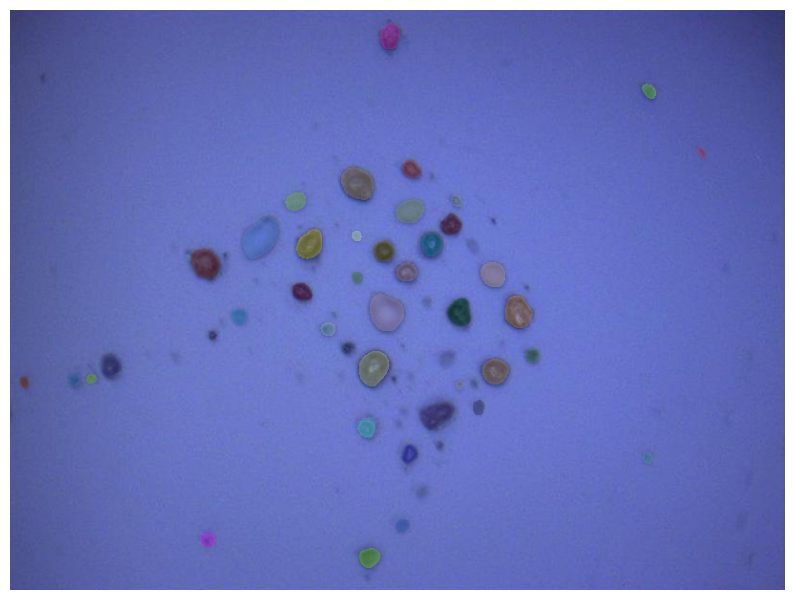

In [39]:
plt.figure(figsize=(10,10))
plt.imshow(images[1])
show_anns(mask[1:])
plt.axis('off')
plt.show() 

In [41]:
mask_true = cv2.imread('annotation_mask/SegmentationObject/MEC_02_038_OPTIR_quartz_3.png')

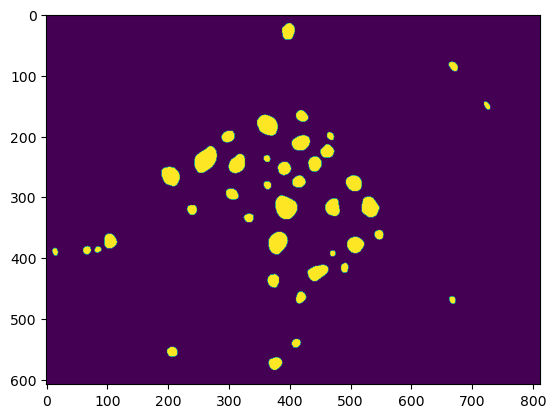

In [254]:
mask_1 = np.array([m['segmentation'] for m in mask[1:]]).sum(0)>0
plt.imshow(mask_1)

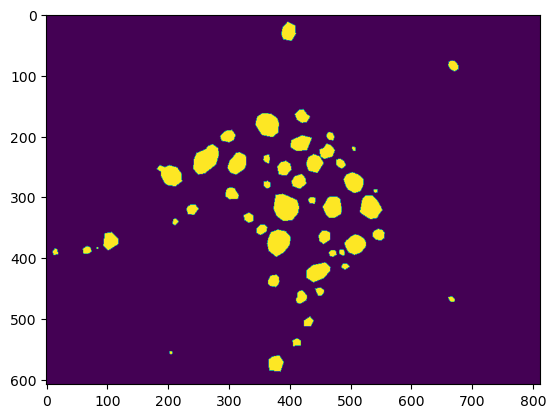

In [253]:
mask_true_0 = [[np.any([(mask_true[i,j] == p).all() for p in particles[1:]]) for i in range(608)] for j in range(812)]
mask_true_1 = np.array(mask_true_0).T
plt.imshow(mask_true_1)

In [ ]:
iou_1 = np.round(100*np.logical_and(mask_true_1, mask_1).sum() / np.logical_or(mask_true_1, mask_1).sum())
iou_1

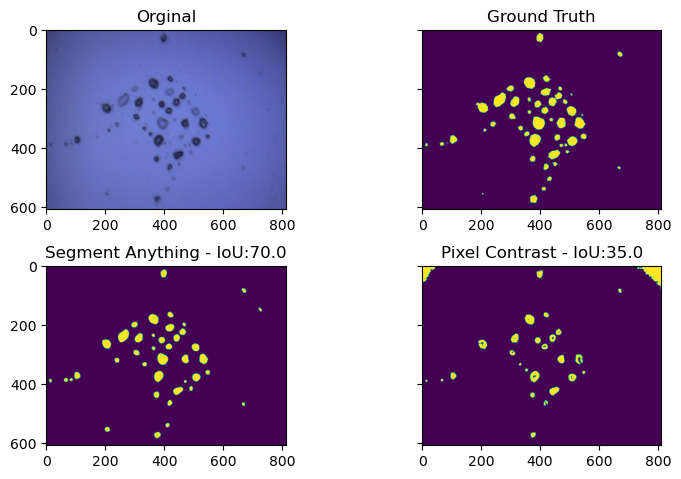

In [400]:
fig, ax = plt.subplots(nrows=2, ncols=2, sharey=True)
fig.set_figheight(5)
fig.set_figwidth(8)
fig.tight_layout(pad=2.0)

_ = ax[0,0].imshow(images[1])
_ = ax[0,0].title.set_text('Orginal')
_ = ax[0,1].imshow(mask_true_1)
_ = ax[0,1].title.set_text('Ground Truth')
_ = ax[1,0].imshow(mask_1)
_ = ax[1,0].title.set_text('Segment Anything - IoU:' + str(iou_1))
_ = ax[1,1].imshow(mask_2)
_ = ax[1,1].title.set_text('Pixel Contrast - IoU:' + str(iou_2))
fig.savefig('performance_test.png')

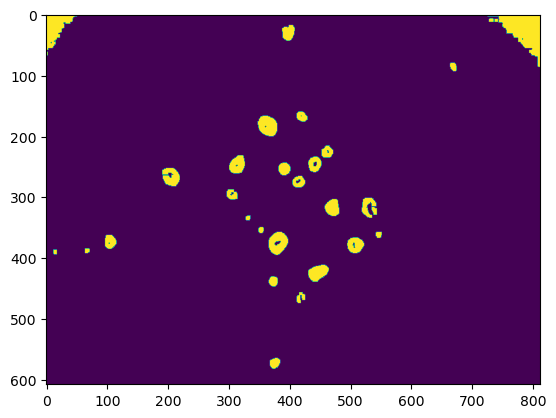

In [345]:
plt.imshow(mask_2)

In [205]:
mask_true_f = mask_true.reshape(608 * 812, 3)
particles = np.unique(mask_true_f, axis=0)#[mask_true_f.sum(1) > 0]

In [259]:
(mask_true_1 == mask_1).mean()

0.986949458776251

In [399]:
iou_1 = np.round(100*np.logical_and(mask_true_1, mask_1).sum() / np.logical_or(mask_true_1, mask_1).sum())

iou_2 = np.round(100*np.logical_and(mask_true_1, mask_2).sum() / np.logical_or(mask_true_1, mask_2).sum())

0.3471705502251811

In [6]:
data_path = "/Users/eochoa/Documents/Research_Ambuj/learning/VAS/xView/train_images/"
input_path_list = os.listdir(data_path)
img = input_path_list[0]
chip_name = data_path + img
images_1 = [cv2.imread(x) for x in [chip_name]]
images_1 = [cv2.cvtColor(image, cv2.COLOR_BGR2RGB) for image in images_1]

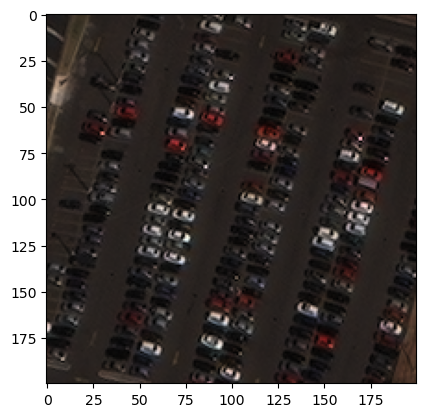

In [19]:
plt.imshow(images_1[0][600:800, 100:300])

In [20]:
mask_generator = SamAutomaticMaskGenerator(sam)
mask = mask_generator.generate(images_1[0][600:800, 100:300])

In [428]:
predictor = SamPredictor(sam)
predictor.set_image(images[0][50:200, 0:300])
#masks, _, _ = predictor.predict(<input_prompts>)
output = predictor.predict()

In [433]:
images[0][50:200, 0:300].shape

(150, 300, 3)

In [442]:
input_point = np.array([[100, 100]])

In [436]:
input_point

array([[ 50, 150]])

In [445]:
input_point = np.array([[100, 100]])
input_label = np.array([1])

masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True,
)

In [460]:
mask_input = logits[1]

In [457]:
scores

array([0.9100495, 0.9913001, 0.8218043], dtype=float32)

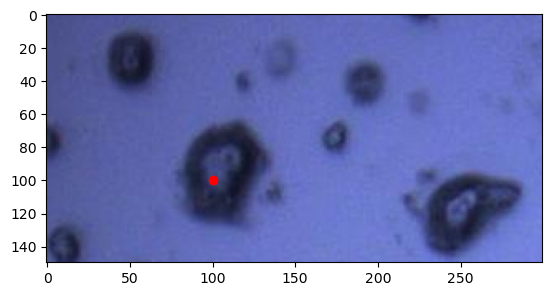

In [443]:
plt.imshow(images[0][50:200, 0:300])
plt.scatter(input_point[0,0], input_point[0,1],c='r')

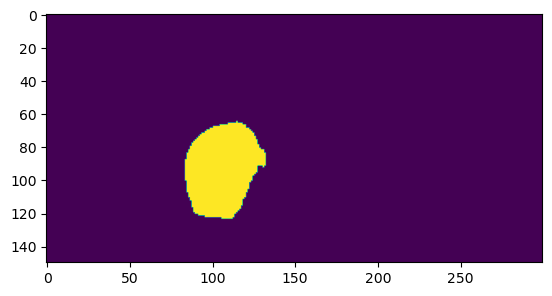

In [452]:
plt.imshow(masks[1])

In [461]:
masks, _, _ = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    mask_input=mask_input[None, :, :],
    multimask_output=False,
)

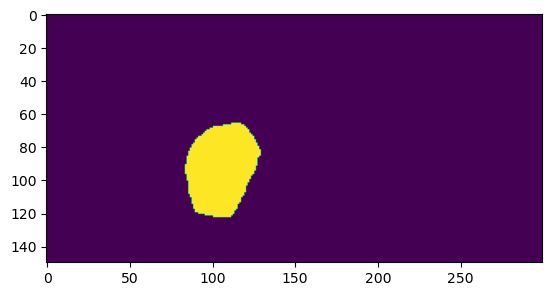

In [464]:
plt.imshow(masks[0])

In [ ]:
mask_generator = SamAutomaticMaskGenerator(sam)
masks = []
for image in tqdm(images):
  masks.append(mask_generator.generate(image))

 94%|█████████▍| 17/18 [02:42<00:10, 10.28s/it]

In [ ]:
import pickle

file_name = "masks.pkl"
#open_file = open(file_name, "wb")
open_file = open(os.path.join(GOOGLE_DRIVE_PATH, file_name), "wb")
pickle.dump(masks, open_file)
open_file.close()

In [12]:
import pickle

file_name = "masks.pkl"
open_file = open(file_name, "rb")
masks = pickle.load(open_file)
open_file.close()

In [13]:
def show_anns(anns):
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)
    ax = plt.gca()
    ax.set_autoscale_on(False)
    polygons = []
    color = []
    for ann in sorted_anns:
        m = ann['segmentation']
        img = np.ones((m.shape[0], m.shape[1], 3))
        color_mask = np.random.random((1, 3)).tolist()[0]
        for i in range(3):
            img[:,:,i] = color_mask[i]
        ax.imshow(np.dstack((img, m*0.35)))

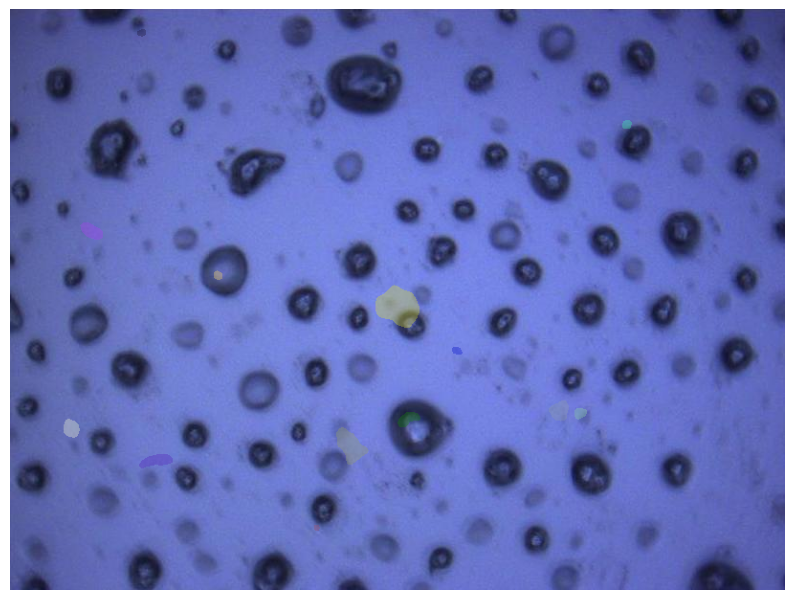

In [34]:
plt.figure(figsize=(10,10))
plt.imshow(images[0])
show_anns(masks[13][1:])
plt.axis('off')
plt.show() 

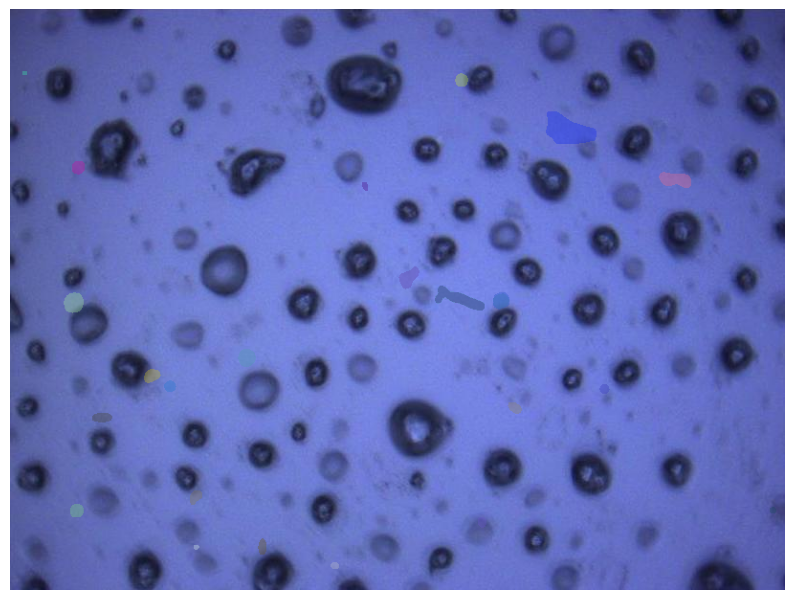

In [14]:
plt.figure(figsize=(10,10))
plt.imshow(images[0])
show_anns(masks[0][1:])
plt.axis('off')
plt.show() 

In [ ]:
plt.figure(figsize=(5,5))
i=1
for image, mask in zip(images, masks):
  plt.imshow(image)
  show_anns(mask[1:])
  plt.axis('off')
  plt.savefig(os.path.join(GOOGLE_DRIVE_PATH, 'masks_segment_anything', 'image_'+str(i)+'.png'))
  plt.show() 
  i=i+1

Output hidden; open in https://colab.research.google.com to view.

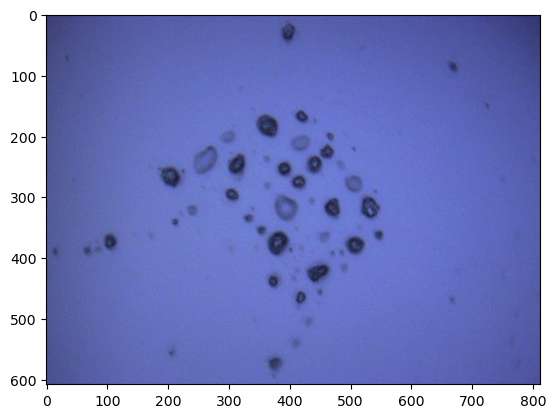

In [277]:
image = images[1]
plt.imshow(image)
#grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
#cv2.imshow('Grayscale', grayscale)

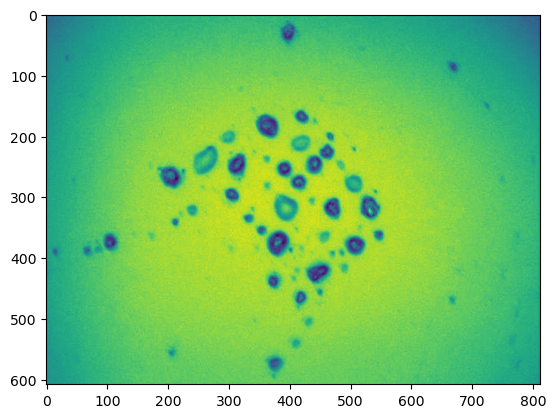

In [278]:
grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(grayscale)

(array([   320.,   2274.,   3428.,   4814.,  11236.,  42090.,  97638.,
        155942., 165238.,  10716.]),
 array([ 34. ,  46.7,  59.4,  72.1,  84.8,  97.5, 110.2, 122.9, 135.6,
        148.3, 161. ]),
 <BarContainer object of 10 artists>)

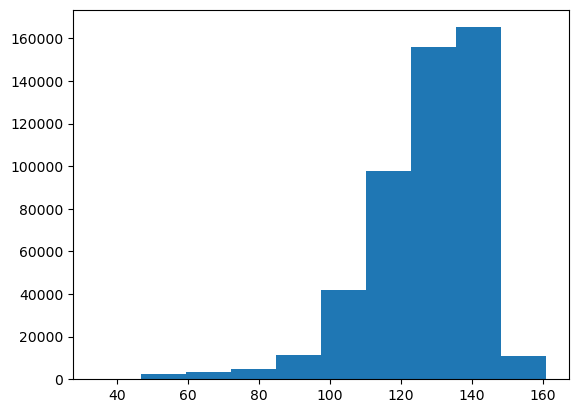

In [279]:
plt.hist(grayscale.flatten())

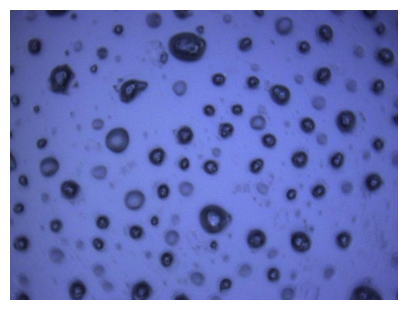

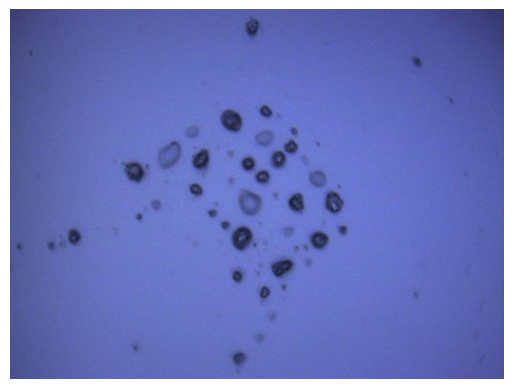

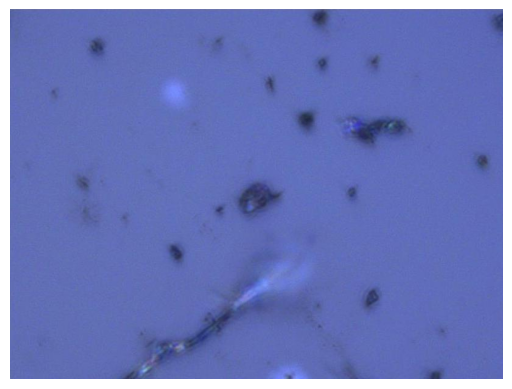

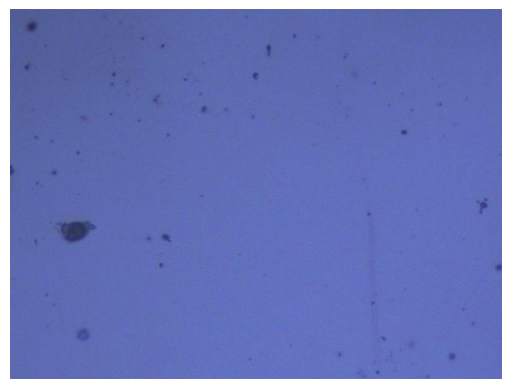

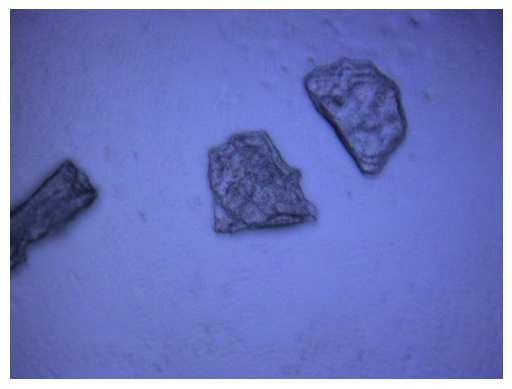

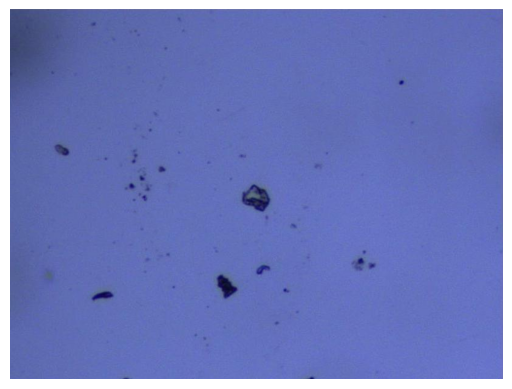

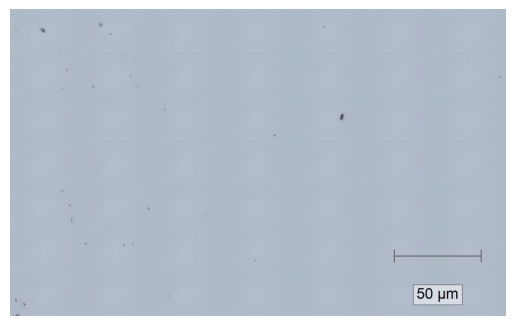

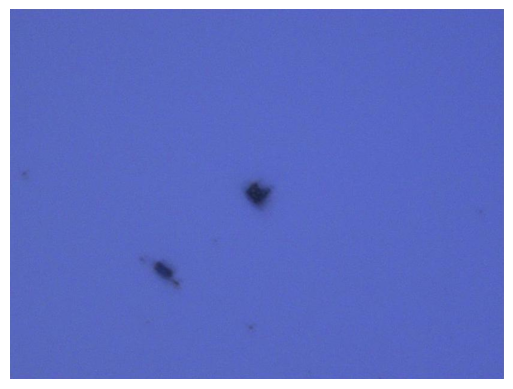

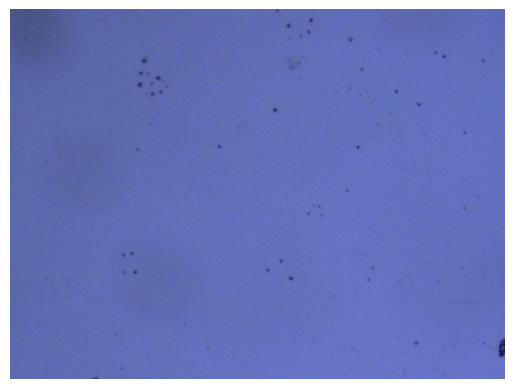

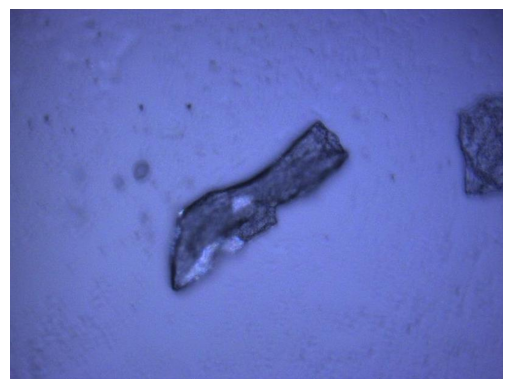

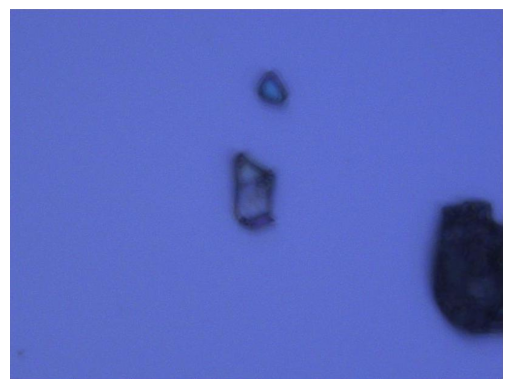

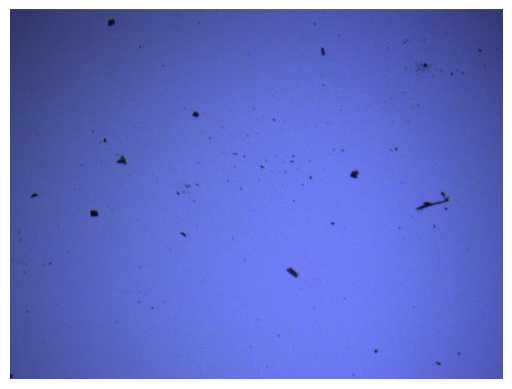

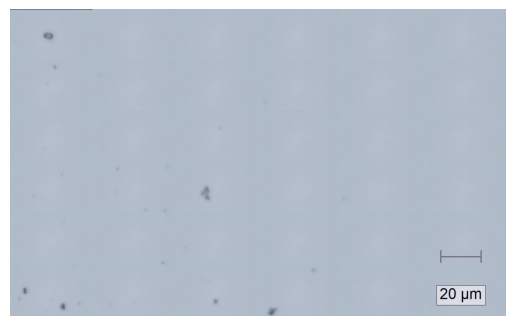

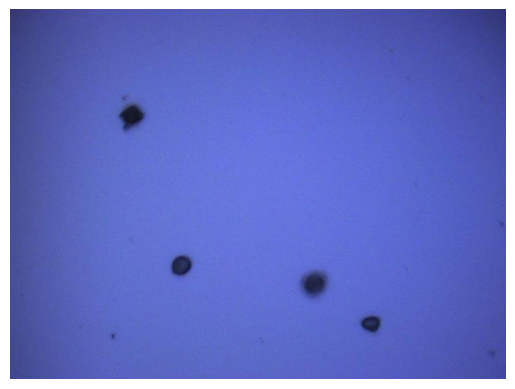

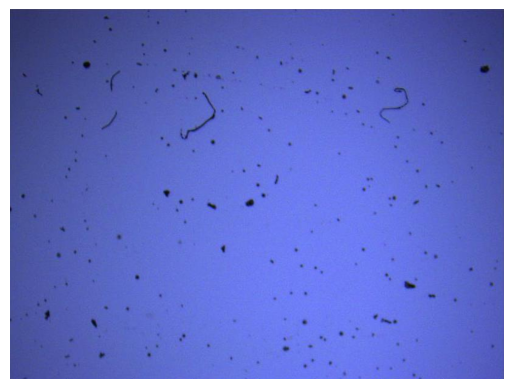

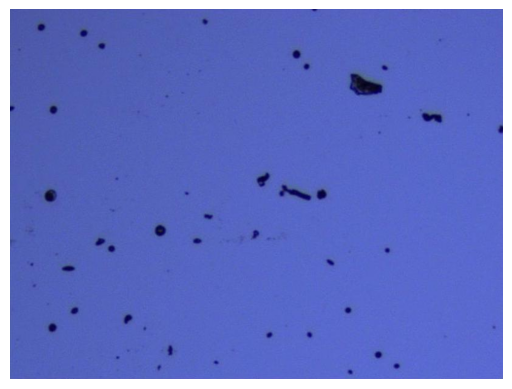

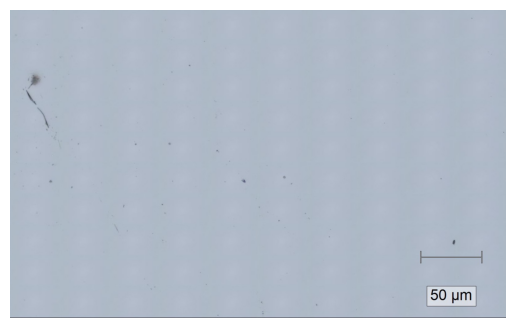

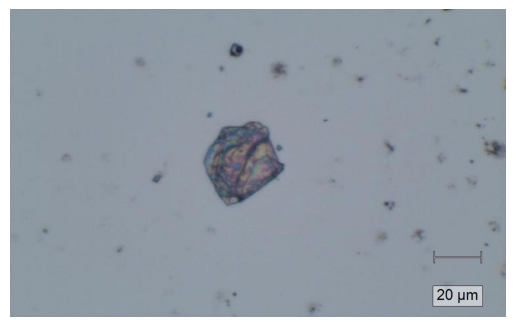

In [21]:
plt.figure(figsize=(5,5))
for image in images:
  plt.imshow(image)
  plt.axis('off')
  plt.show()

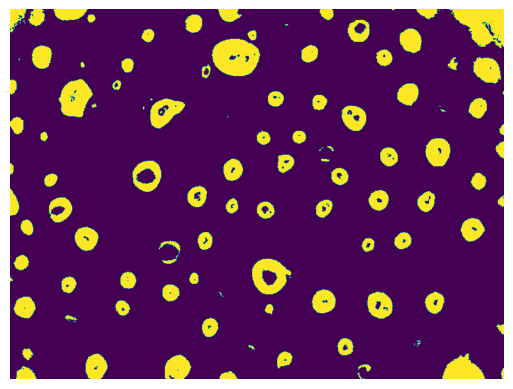

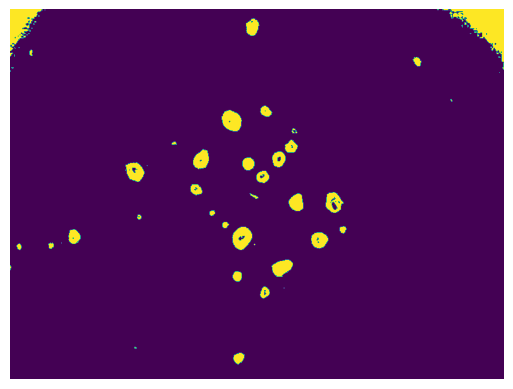

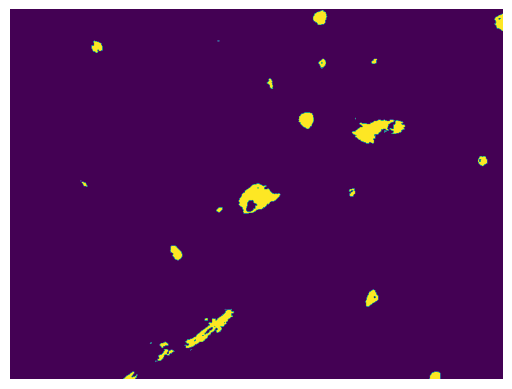

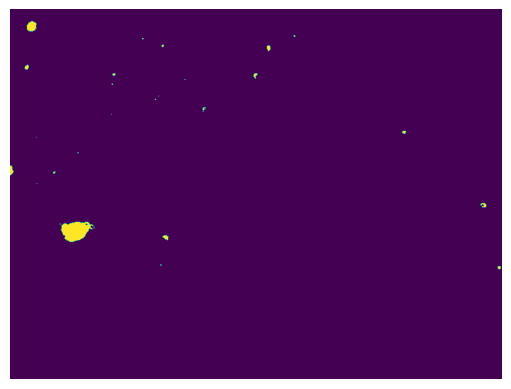

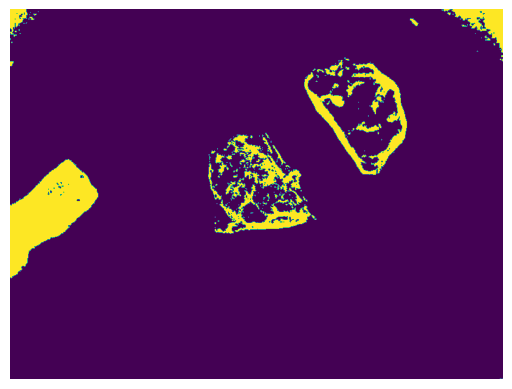

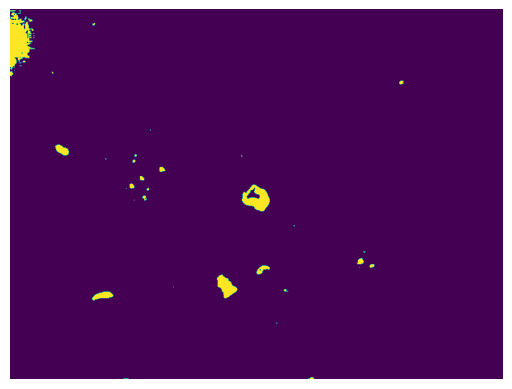

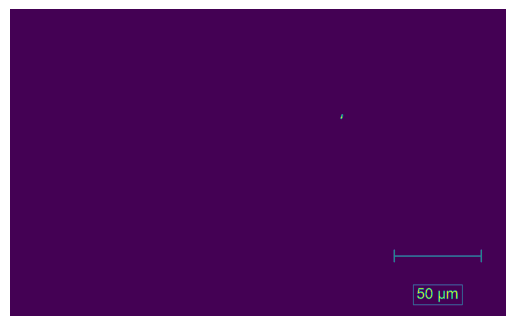

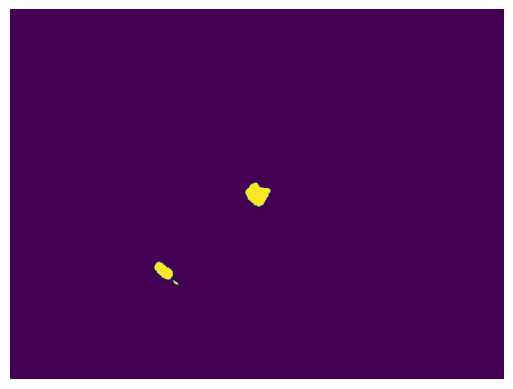

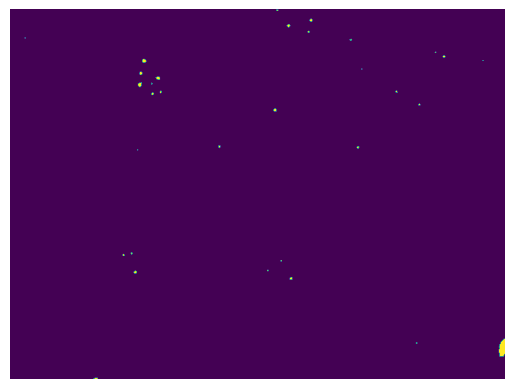

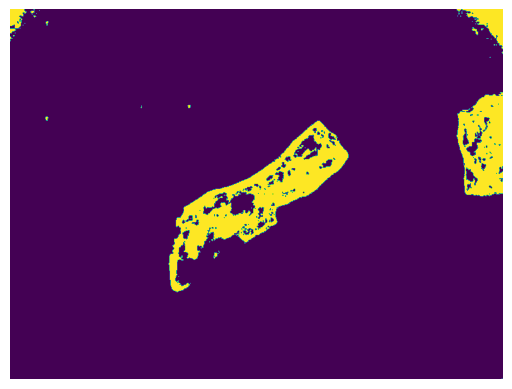

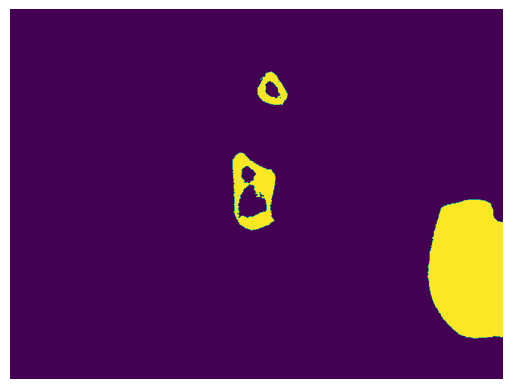

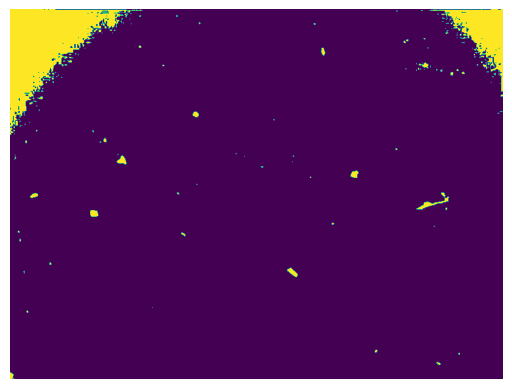

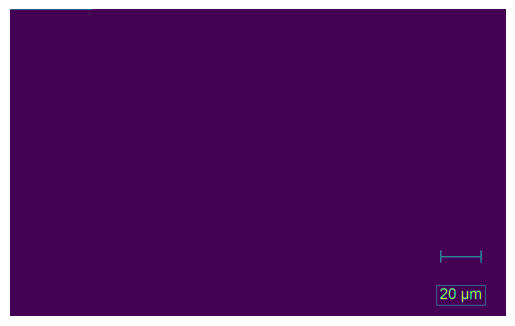

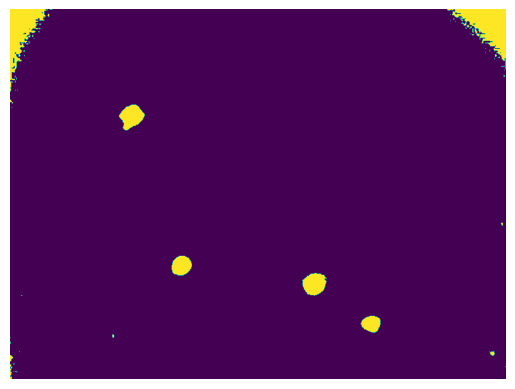

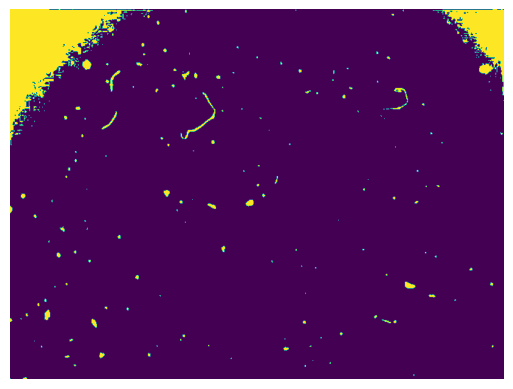

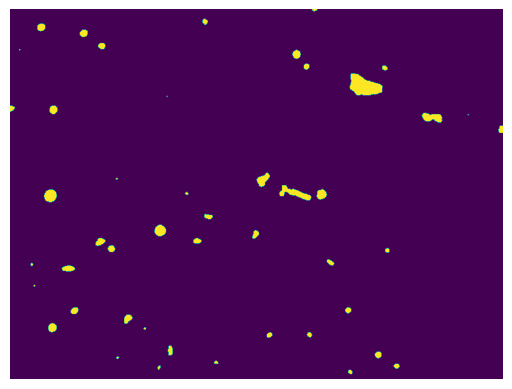

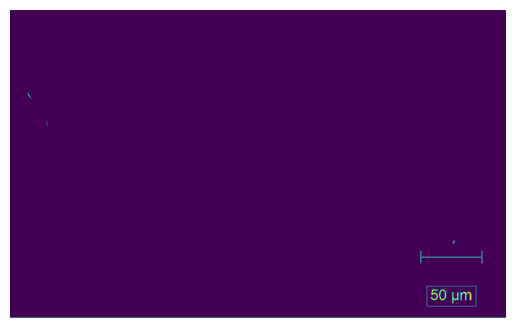

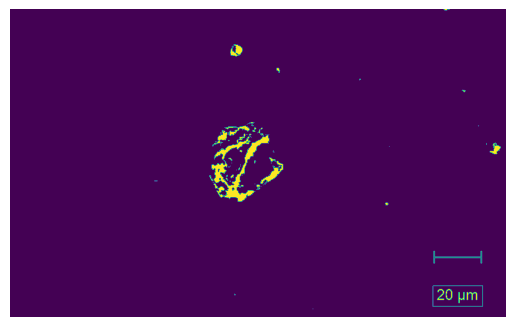

In [307]:
low = np.array([0])
high = np.array([90])

for image in images:
    grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    mask = cv2.inRange(grayscale, low, high)

    plt.axis('off')
    plt.imshow(mask)

    result = cv2.bitwise_and(image, image, mask=255 - mask)

    #plt.imshow(result)
  
    plt.show()

In [308]:
mask

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], dtype=uint8)

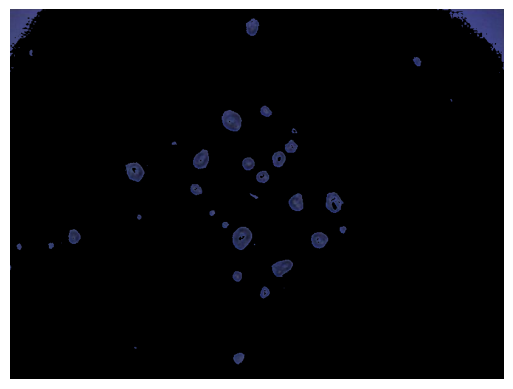

In [310]:
image = images[1]
grayscale = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
mask = cv2.inRange(grayscale, low, high)

result = cv2.bitwise_and(image, image, mask=mask)

plt.axis('off')
plt.imshow(result)

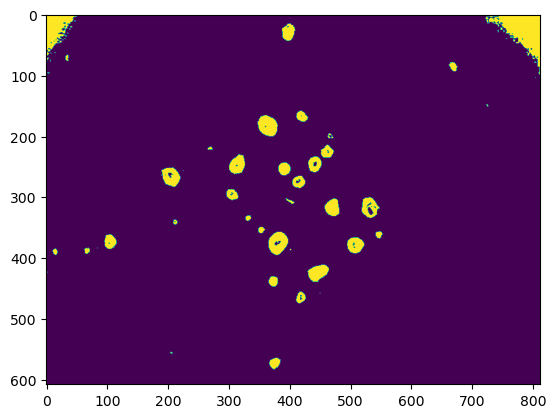

In [369]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
low = np.array([0])
high = np.array([90])
#img = cv.imread('coins.png')
#assert img is not None, "file could not be read, check with os.path.exists()"
gray = cv.cvtColor(image,cv.COLOR_BGR2GRAY)
ret, thresh = cv.threshold(gray,0,255, 9)#,cv.THRESH_BINARY_INV+cv.THRESH_OTSU)
thresh = cv2.inRange(grayscale, low, high)
plt.imshow(thresh)

In [336]:
# noise removal
kernel = np.ones((3,3),np.uint8)
opening = cv.morphologyEx(thresh,cv.MORPH_OPEN,kernel, iterations = 2)
# sure background area
sure_bg = cv.dilate(opening,kernel,iterations=3)
# Finding sure foreground area
dist_transform = cv.distanceTransform(opening,cv.DIST_L2,5)
ret, sure_fg = cv.threshold(dist_transform,0.7*dist_transform.max(),255,0)
# Finding unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv.subtract(sure_bg,sure_fg)

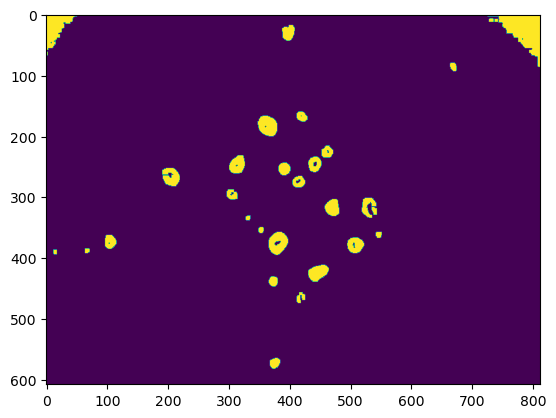

In [337]:
plt.imshow(opening)

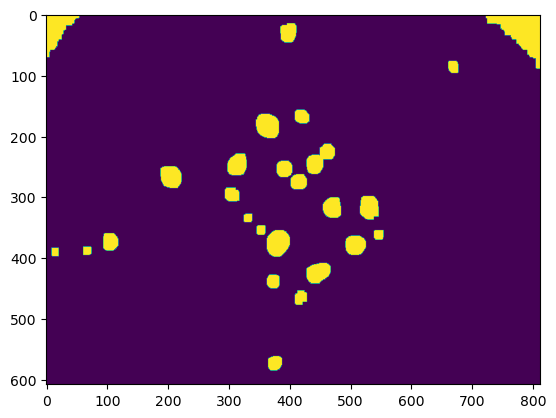

In [338]:
plt.imshow(sure_bg)

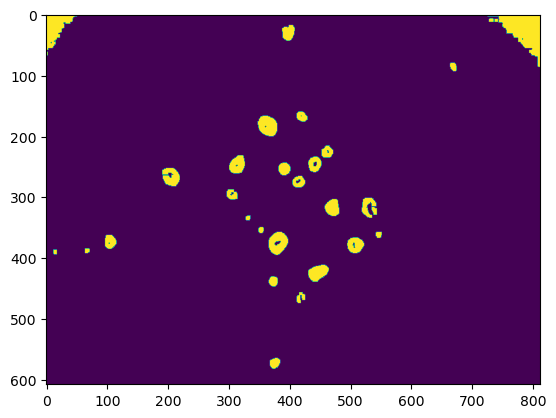

In [339]:
dist_transform = cv.distanceTransform(opening,cv.DIST_L2,5)
ret, sure_fg = cv.threshold(dist_transform,0.01*dist_transform.max(),255,0)

plt.imshow(sure_fg)

In [343]:
mask_2 = (sure_fg==255)

In [323]:
sure_fg = np.uint8(sure_fg)
unknown = cv.subtract(sure_bg,sure_fg)

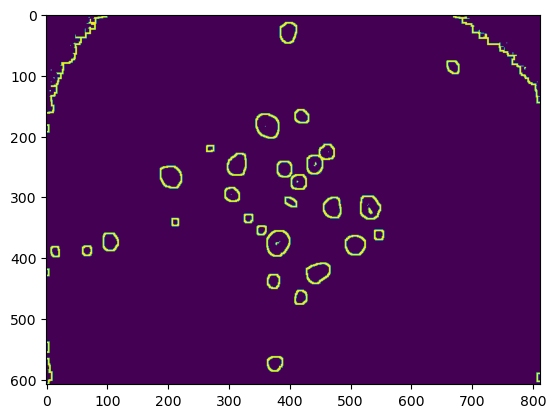

In [324]:
plt.imshow(unknown)

In [325]:
# Marker labelling
ret, markers = cv.connectedComponents(sure_fg)
# Add one to all labels so that sure background is not 0, but 1
markers = markers+1
# Now, mark the region of unknown with zero
markers[unknown==255] = 0

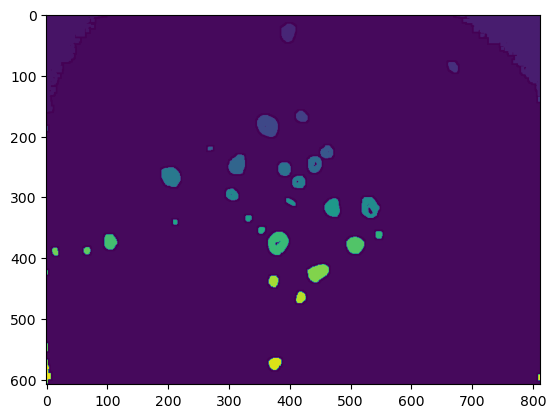

In [326]:
plt.imshow(markers)

In [327]:
markers = cv.watershed(image,markers)
image[markers == -1] = [255,0,0]

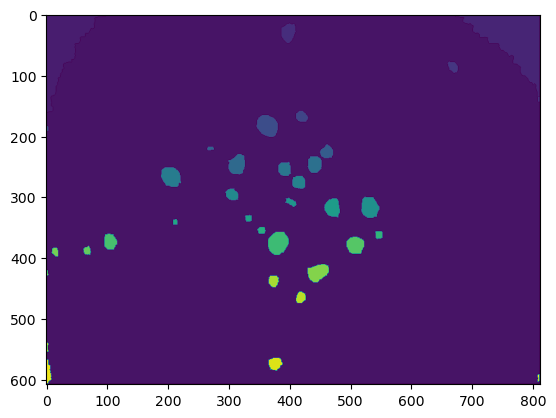

In [328]:
plt.imshow(markers)

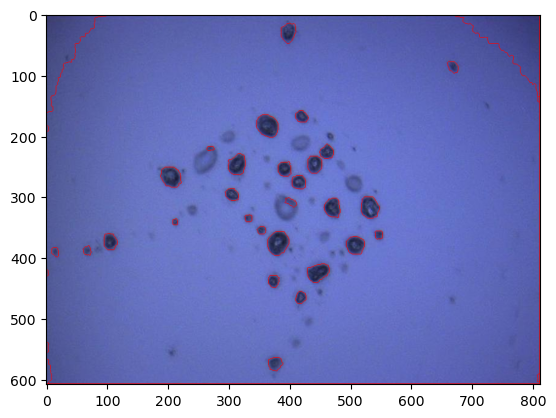

In [329]:
plt.imshow(image)